# 04 — linear regression baseline

starting simple. linear regression, then ridge and lasso to see if regularization helps. everything compared using RMSE and R².

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score

from src.train import train_model, cross_val_rmse
from src.evaluate import evaluate, plot_residuals

sns.set_theme(style='whitegrid')

train = pd.read_csv('../data/processed/train.csv')
test  = pd.read_csv('../data/processed/test.csv')

X_train = train.drop(columns=['price']).values
y_train = train['price'].values
X_test  = test.drop(columns=['price']).values
y_test  = test['price'].values

feature_names = train.drop(columns=['price']).columns.tolist()
print(f"features: {len(feature_names)}  train: {X_train.shape[0]}  test: {X_test.shape[0]}")

features: 11  train: 16512  test: 4128


## linear regression

In [2]:
lr = train_model(X_train, y_train, model_type='linear')
pred_lr = lr.predict(X_test)

results = []
results.append(evaluate(y_test, pred_lr, label='Linear Regression'))

Linear Regression — RMSE: 0.6760  R²: 0.6513


In [3]:
# cross-val RMSE gives a more honest picture than just test RMSE
cv_rmse_lr = cross_val_rmse(lr, X_train, y_train)
print(f"Linear Regression — 5-fold CV RMSE: {cv_rmse_lr:.4f}")

Linear Regression — 5-fold CV RMSE: 0.6689


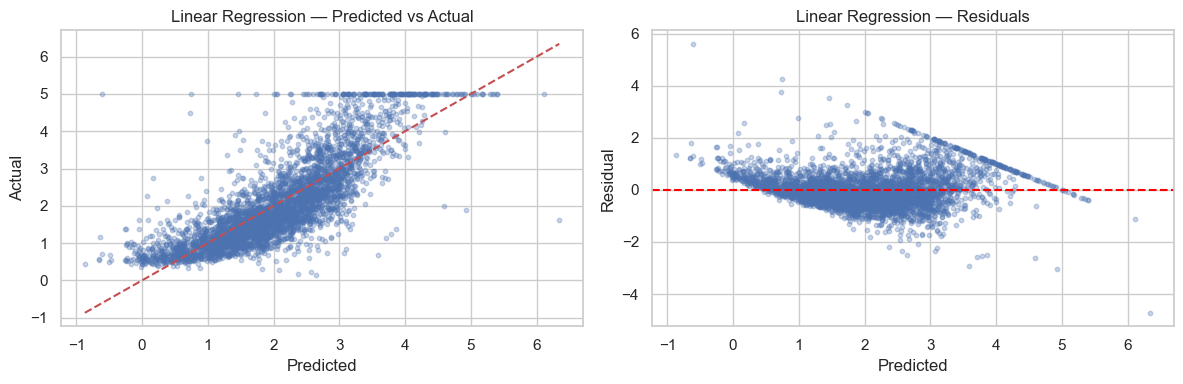

In [4]:
plot_residuals(y_test, pred_lr, label='Linear Regression')

## ridge regression

ridge adds L2 penalty — shrinks coefficients but doesn't zero them out. good when features are correlated.

In [5]:
# tune alpha — higher alpha = more regularization
alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]
ridge_cv_scores = []

for a in alphas:
    r = Ridge(alpha=a)
    score = cross_val_rmse(r, X_train, y_train)
    ridge_cv_scores.append(score)
    print(f"  alpha={a:>6} → CV RMSE: {score:.4f}")

  alpha=  0.01 → CV RMSE: 0.6689
  alpha=   0.1 → CV RMSE: 0.6689
  alpha=   1.0 → CV RMSE: 0.6690
  alpha=  10.0 → CV RMSE: 0.6692
  alpha=  50.0 → CV RMSE: 0.6700
  alpha= 100.0 → CV RMSE: 0.6717


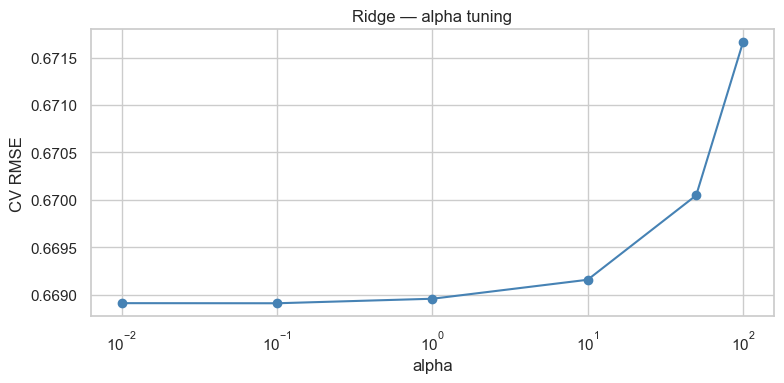

best alpha: 0.1


In [6]:
plt.figure(figsize=(8, 4))
plt.plot(alphas, ridge_cv_scores, marker='o', color='steelblue')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('CV RMSE')
plt.title('Ridge — alpha tuning')
plt.tight_layout()
plt.savefig('../plots/ridge_alpha_tuning.png', dpi=120)
plt.show()

best_ridge_alpha = alphas[np.argmin(ridge_cv_scores)]
print(f"best alpha: {best_ridge_alpha}")

In [7]:
ridge = train_model(X_train, y_train, model_type='ridge', alpha=best_ridge_alpha)
pred_ridge = ridge.predict(X_test)
results.append(evaluate(y_test, pred_ridge, label=f'Ridge (alpha={best_ridge_alpha})'))

Ridge (alpha=0.1) — RMSE: 0.6760  R²: 0.6512


## lasso regression

lasso adds L1 penalty — can zero out coefficients entirely. useful for feature selection.

In [8]:
alphas_lasso = [0.0001, 0.001, 0.01, 0.1, 1.0]
lasso_cv_scores = []

for a in alphas_lasso:
    l = Lasso(alpha=a, max_iter=5000)
    score = cross_val_rmse(l, X_train, y_train)
    lasso_cv_scores.append(score)
    print(f"  alpha={a} → CV RMSE: {score:.4f}")

c:\Users\Agam Katiyar\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.675e+02, tolerance: 1.755e+00
  model = cd_fast.enet_coordinate_descent(
c:\Users\Agam Katiyar\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.397e+02, tolerance: 1.779e+00
  model = cd_fast.enet_coordinate_descent(
c:\Users\Agam Katiyar\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap

  alpha=0.0001 → CV RMSE: 0.6691
  alpha=0.001 → CV RMSE: 0.6692
  alpha=0.01 → CV RMSE: 0.6775
  alpha=0.1 → CV RMSE: 0.7859
  alpha=1.0 → CV RMSE: 1.1563


In [9]:
best_lasso_alpha = alphas_lasso[np.argmin(lasso_cv_scores)]
print(f"best alpha: {best_lasso_alpha}")

lasso = train_model(X_train, y_train, model_type='lasso', alpha=best_lasso_alpha, max_iter=5000)
pred_lasso = lasso.predict(X_test)
results.append(evaluate(y_test, pred_lasso, label=f'Lasso (alpha={best_lasso_alpha})'))

best alpha: 0.0001
Lasso (alpha=0.0001) — RMSE: 0.6768  R²: 0.6504


c:\Users\Agam Katiyar\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.193e+02, tolerance: 2.207e+00
  model = cd_fast.enet_coordinate_descent(


In [10]:
# which features did lasso kill?
zero_coefs = np.sum(lasso.coef_ == 0)
print(f"features zeroed out by Lasso: {zero_coefs} / {len(feature_names)}")

features zeroed out by Lasso: 0 / 11


## coefficient comparison — Linear vs Ridge vs Lasso

In [11]:
coef_df = pd.DataFrame({
    'feature': feature_names,
    'linear': lr.coef_,
    'ridge': ridge.coef_,
    'lasso': lasso.coef_,
}).set_index('feature')

coef_df.round(4)

,linear,ridge,lasso
feature,,,
MedInc,0.7158,0.7158,0.7164
HouseAge,0.1586,0.1584,0.1561
AveRooms,0.0402,0.0326,-0.0511
AveBedrms,-0.2580,-0.2578,-0.2552
Population,-1.5073,-1.4122,-0.2352
AveOccup,0.8468,0.8209,0.4921
Latitude,-0.8945,-0.8947,-0.8978
Longitude,-0.8280,-0.8282,-0.8305
rooms_per_household,0.8696,0.8788,0.9806


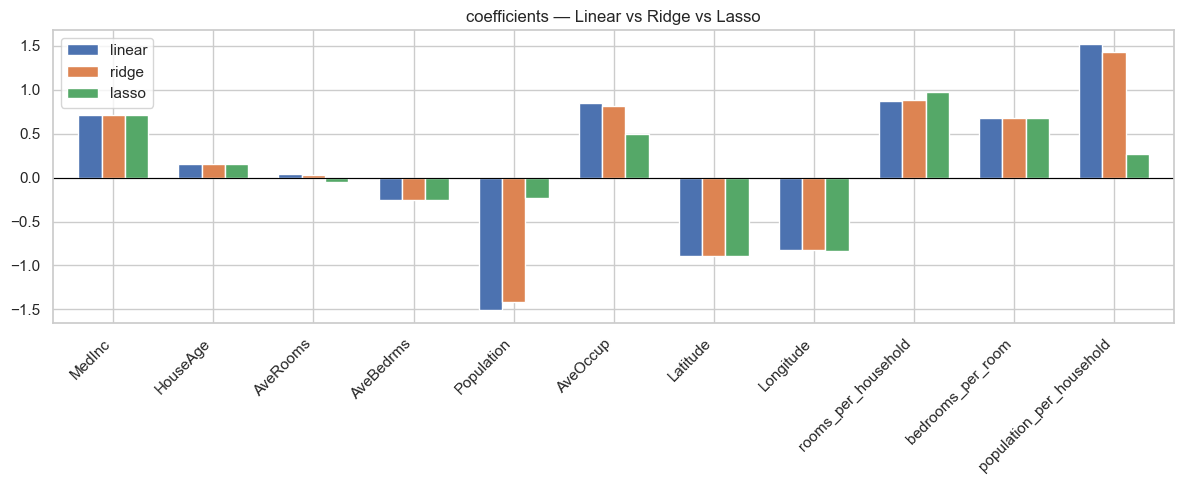

In [12]:
ax = coef_df.plot(kind='bar', figsize=(12, 5), width=0.7)
ax.set_title('coefficients — Linear vs Ridge vs Lasso')
ax.set_xlabel('')
ax.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../plots/coefficients_comparison.png', dpi=120)
plt.show()

## results so far

In [13]:
results_df = pd.DataFrame(results)
results_df.sort_values('rmse')

,model,rmse,r2
0,Linear Regression,0.6760,0.6513
1,Ridge (alpha=0.1),0.6760,0.6512
2,Lasso (alpha=0.0001),0.6768,0.6504


In [14]:
# save best linear model
from src.train import save_model

best_linear = min(
    [('linear', lr, pred_lr), ('ridge', ridge, pred_ridge), ('lasso', lasso, pred_lasso)],
    key=lambda x: np.sqrt(np.mean((y_test - x[2])**2))
)
save_model(best_linear[1], f'../models/{best_linear[0]}.pkl')
print(f"best linear model: {best_linear[0]}")

saved → ../models/linear.pkl
best linear model: linear
